# Statistical analysis: processed dataset

Analyze engineered **training** features before building a classifier. Validation, refit and test data remain unloaded.
Weekly customer snapshots are correlated: pooled rows are prediction instances, not independent customers.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from online_retail.analysis.processed import (
    feature_summary, class_shares, plot_target_over_time,
    plot_feature_distributions, plot_correlations,
    plot_group_outcomes, plot_weekly_feature_medians,
    target_correlations, plot_target_correlations,
)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data/processed"
manifest = json.loads((DATA / "manifest.json").read_text())
train = pd.read_parquet(DATA / "train.parquet")
feature_columns = manifest["feature_columns"]
target = manifest["target"]


## Construction checks

Check keys, cutoff cadence, label availability and schema before interpreting plots.
These checks verify the saved dataset; they do not fit preprocessing or models.


In [2]:
assert not train.duplicated(manifest["keys"]).any()
assert train["cutoff"].dt.dayofweek.eq(0).all()
assert train[target].isin([0, 1, 2]).all()
assert (train["cutoff"] + pd.Timedelta(days=manifest["horizon_days"])
        <= pd.Timestamp(manifest["settings"]["validation_start"])).all()
assert set(feature_columns).isdisjoint([*manifest["keys"], target])
assert not train[feature_columns].select_dtypes("number").isin([float("inf"), -float("inf")]).any().any()

pd.Series({"customer_snapshots": len(train), "distinct_customers": train["Customer ID"].nunique(),
           "weekly_cutoffs": train["cutoff"].nunique(),
           "first_cutoff": train["cutoff"].min(), "last_cutoff": train["cutoff"].max()})


/tmp/ipykernel_178370/588405658.py:4: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert (train["cutoff"] + pd.Timedelta(days=manifest["horizon_days"])


customer_snapshots                  92319
distinct_customers                   3687
weekly_cutoffs                         33
first_cutoff          2010-03-01 00:00:00
last_cutoff           2010-10-11 00:00:00
dtype: object

## Feature coverage, missingness and ranges

Missing purchase gaps are expected for customers with limited purchase-day history.
Missing is not a zero-day gap. Check unusually large values without automatically
removing them: wholesale customers may legitimately have large baskets.


In [3]:
summary = feature_summary(train, feature_columns)
summary

,dtype,missing_pct,unique_values,min,50%,95%,99%,max
invoice_count,int64,0.000000,107,1.000000,2.000000e+00,9.000000,23.000000,148.000000
purchase_day_count,int64,0.000000,88,1.000000,2.000000e+00,8.000000,18.000000,94.000000
monetary_total,float64,0.000000,10481,1.300000,5.297900e+02,4261.202000,14481.970000,269041.670000
recency_days,float64,0.000000,52194,0.314583,5.161597e+01,206.267778,271.300583,313.586806
observed_history_days,float64,0.000000,65295,0.318056,1.303639e+02,276.500833,304.285042,313.677083
mean_gap_days,float64,46.264583,2073,1.000000,4.500000e+01,140.000000,204.000000,306.000000
std_gap_days,float64,67.226681,4319,0.000000,1.909188e+01,67.175144,106.066017,193.040151
average_invoice_value,float64,0.000000,10445,1.300000,2.926600e+02,940.002857,2013.470000,13280.460000
average_units_per_invoice,float64,0.000000,4928,1.000000,1.500000e+02,600.000000,1359.000000,87167.000000
distinct_product_count,int64,0.000000,573,1.000000,2.900000e+01,154.000000,280.820000,1520.000000


In [4]:
gap_columns = ["last_gap_days", "gap_2_span_days", "gap_3_span_days", "mean_gap_days", "std_gap_days"]
history_bands = pd.cut(train["purchase_day_count"], bins=[0, 1, 2, 3, float("inf")],
                       labels=["1 day", "2 days", "3 days", "4+ days"])
train[gap_columns].isna().groupby(history_bands, observed=True).mean().mul(100).round(1)


,last_gap_days,gap_2_span_days,gap_3_span_days,mean_gap_days,std_gap_days
purchase_day_count,,,,,
1 day,100.0,100.0,100.0,100.0,100.0
2 days,0.0,100.0,100.0,0.0,100.0
3 days,0.0,0.0,100.0,0.0,0.0
4+ days,0.0,0.0,0.0,0.0,0.0


**Interpretation.** Around 46.3% of pooled training snapshots lack a latest purchase-day gap,
and 67.2% lack gap standard deviation. This reflects limited repeat history, rather
than a value to replace with zero. A standard deviation needs at least two completed
gaps (three purchase days). Keep these customers and handle missing values within
training folds later.


## Target balance and change over time

Class 0: days 0–20; class 1: days 21–49; class 2: no purchase within 50 days.
Compare pooled balance with weekly balance. Later cutoffs include more customers;
long-inactive customers remain eligible. Accuracy alone may hide a dominant class.


In [5]:
class_counts = train[target].value_counts().reindex([0, 1, 2], fill_value=0).rename("snapshots")
class_table = class_counts.to_frame()
class_table["share_pct"] = class_counts / len(train) * 100
class_table


,snapshots,share_pct
NextPurchaseRange,,
0,19439,21.056337
1,17056,18.475070
2,55824,60.468593


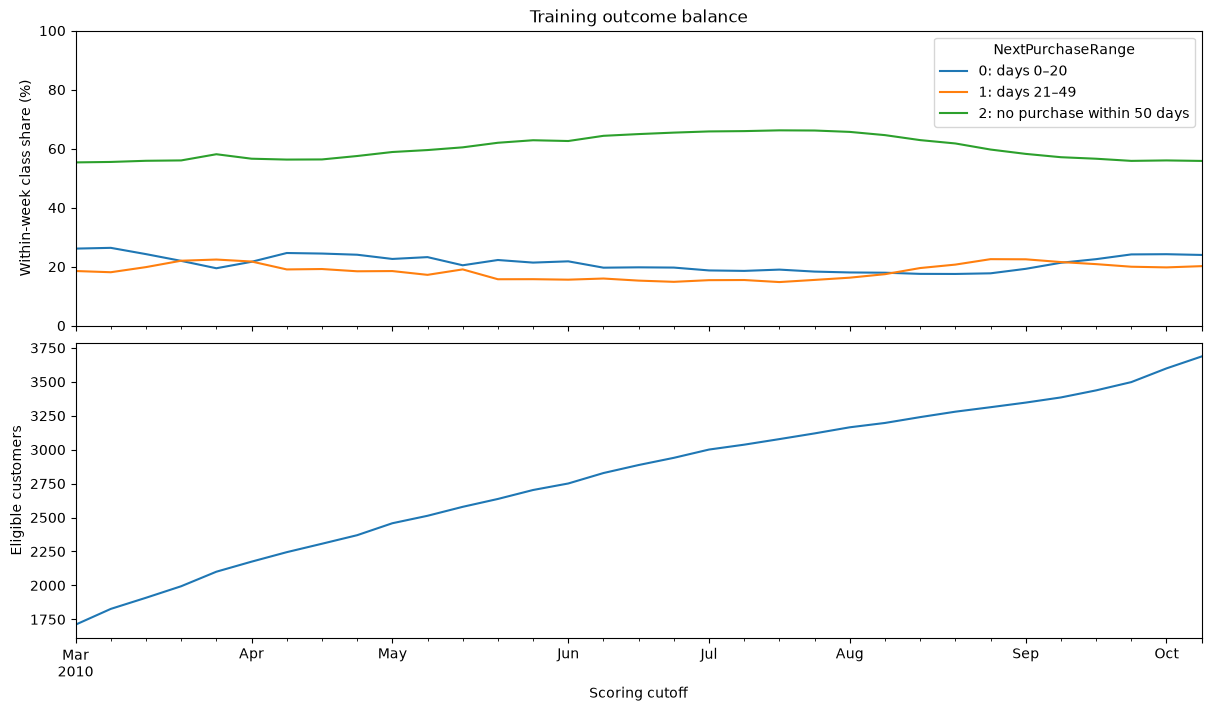

In [6]:
plot_target_over_time(train, target)
plt.show()


**Interpretation.** Class 2 accounts for about 60.5% of training snapshots, compared
with 21.1% for class 0 and 18.5% for class 1. A constant class-2 prediction therefore
provides a substantial accuracy baseline. The weekly plot shows whether that pooled
balance conceals changes over time; repeated customer weeks are not independent.


## Distributions for one customer population

Use the last training cutoff (one row per customer). Invoice count and spending
use base-10 logarithmic x-axes with ticks in original units (1, 10, 100, 1,000...).
Their bins are equally spaced on the log axis: each covers the same multiplicative
range, not the same absolute width. Bar heights show customer counts, not density.
Recency, observed history, purchase gaps and recent invoice counts stay linear.
In particular, recent counts retain meaningful zeros; zero cannot lie on a log axis.
Missing gaps are omitted, not replaced by zero. No model features are transformed.


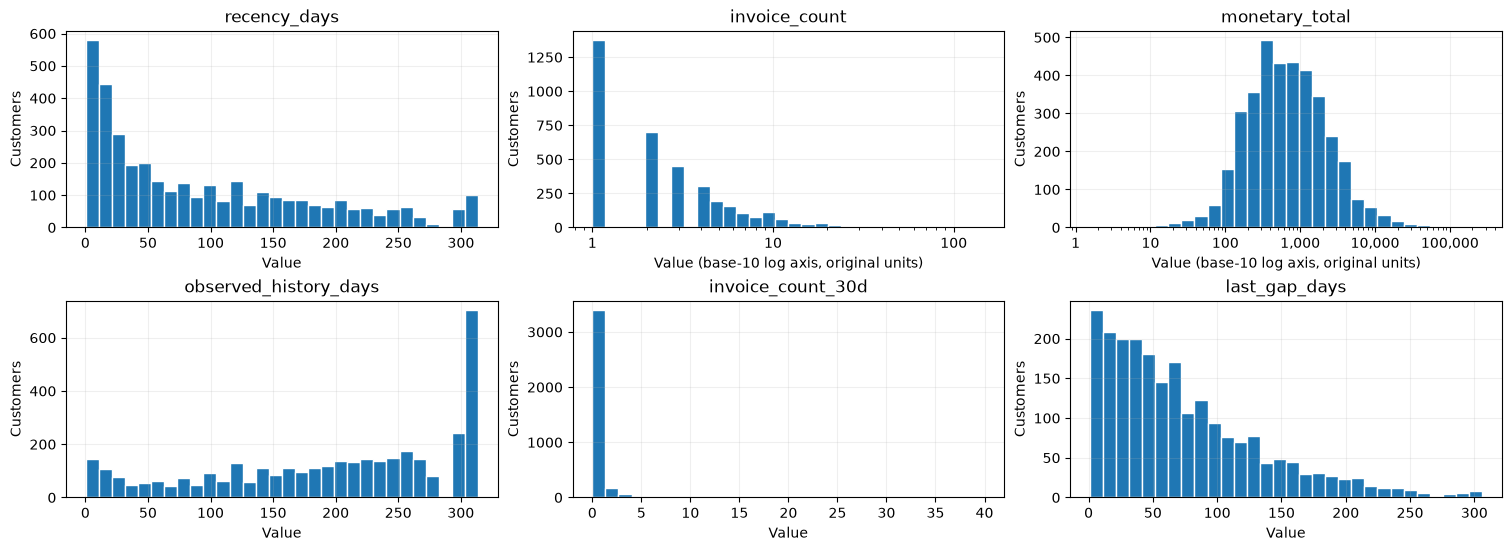

In [7]:
important_features = [
    "recency_days", "invoice_count", "monetary_total",
    "observed_history_days", "invoice_count_30d", "last_gap_days",
]
last_cutoff = train["cutoff"].max()
latest_train = train.loc[train["cutoff"].eq(last_cutoff)]
plot_feature_distributions(latest_train, important_features)
plt.show()


**Interpretation (2010-10-11).** The median customer has 2 invoices and recorded spend
of £631.79; the 99th percentiles are 28 invoices and about £18,068. The long right
tails explain the logarithmic axes: a few large buyers should not compress the bulk
of customers into the first bar. Large values alone do not establish errors.

About 65.8% of these customers have no invoice in the preceding 30 days. Median
recency is about 62 days. The median latest completed gap is 57 days **among customers
with a defined gap**; it does not describe the return time of all customers.


## Predictor relationships

Show the six core features plus recent spend and the combined RFM score.
Annotated Spearman correlations describe monotonic associations using pairwise
nonmissing rows. RFM score is derived from other predictors, so some correlation
is expected. Correlation is not model importance or a reason to automatically
remove a feature. Other predictors remain in the saved datasets.


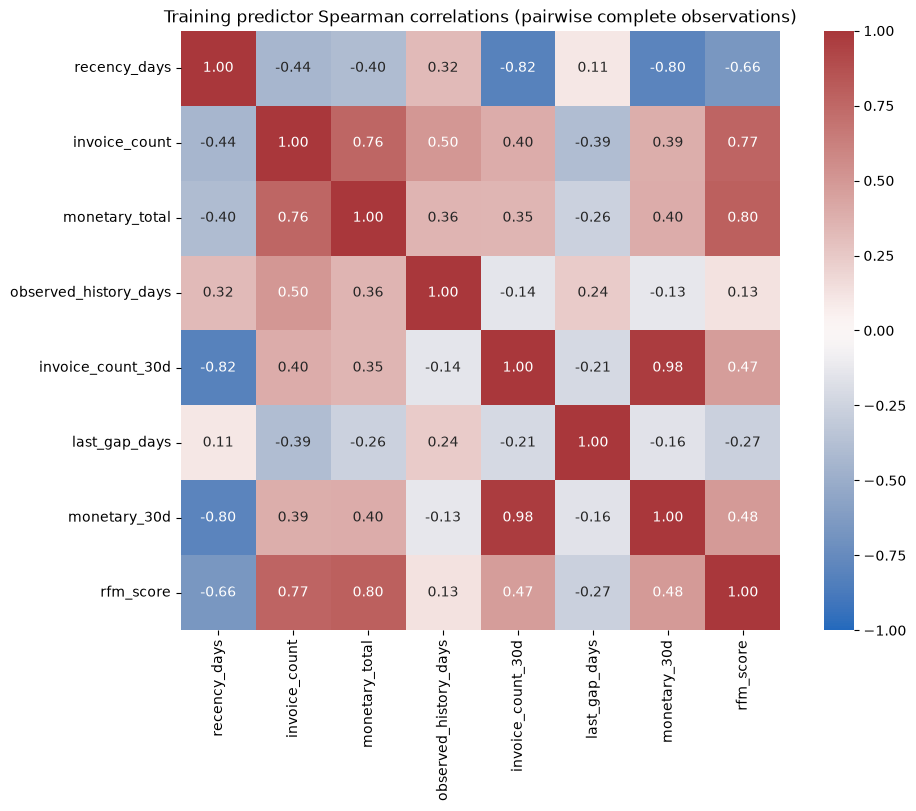

In [8]:
relationship_features = important_features + ["monetary_30d", "rfm_score"]
plot_correlations(train, relationship_features)
plt.show()


**Interpretation.** Historical invoice count and spend are strongly associated
(Spearman ≈ 0.76). Recent invoice count and recent spend are even more closely
associated (≈ 0.98), partly because both are zero for inactive customers. Recency
is strongly negatively associated with recent invoice count (≈ −0.82), as expected.
RFM score is derived from its components, so its correlations are not new independent
evidence. Retain these candidates until chronological model comparisons establish
whether removing redundant features helps.


## Associations with each target class

Each target column is an indicator: 1 when that class occurred, 0 otherwise.
Positive correlation means larger feature values tend to accompany that outcome;
negative correlation means the opposite. We do not treat labels 0/1/2 as a numeric
purchase time. Missing features are excluded pairwise; see available-row counts.
These are pooled training associations across correlated weekly snapshots, not
causal effects, independent significance tests, or out-of-time model performance.


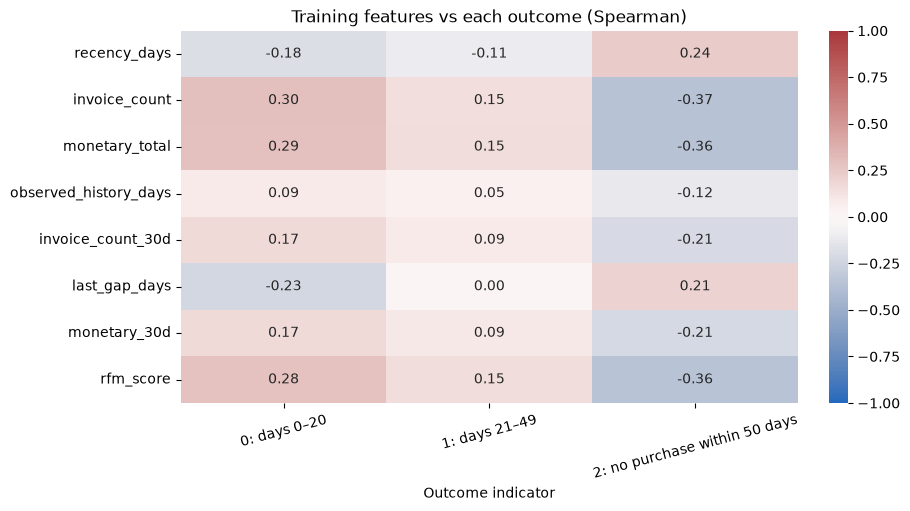

In [9]:
outcome_correlations = target_correlations(train, relationship_features, target)
plot_target_correlations(outcome_correlations)
plt.show()


In [10]:
# Counts clarify that gap correlations describe a subset with observed repeat history.
train[relationship_features].notna().sum().rename("available_snapshots").to_frame()


,available_snapshots
recency_days,92319
invoice_count,92319
monetary_total,92319
observed_history_days,92319
invoice_count_30d,92319
last_gap_days,49608
monetary_30d,92319
rfm_score,92319


**Interpretation.** Higher historical frequency and spend are associated with class 0
(≈ 0.30 and 0.29) and negatively associated with class 2 (≈ −0.37 and −0.36).
Higher recency is associated with class 2 (≈ 0.24). Class-1 associations are generally
weaker: distinguishing intermediate timing may be harder than identifying non-return
within the horizon. Latest-gap associations apply only to repeat-history snapshots.
These are descriptive correlations, not predictive performance or campaign effects.


## Historical associations with outcomes

Bars below describe pooled training snapshots, not classifier predictions.
Compare sparse histories, recency groups, and relative RFM segments. These patterns
are not campaign effects. Feature summaries by class are descriptive; avoid p-values
that treat repeated customer-weeks as independent observations.


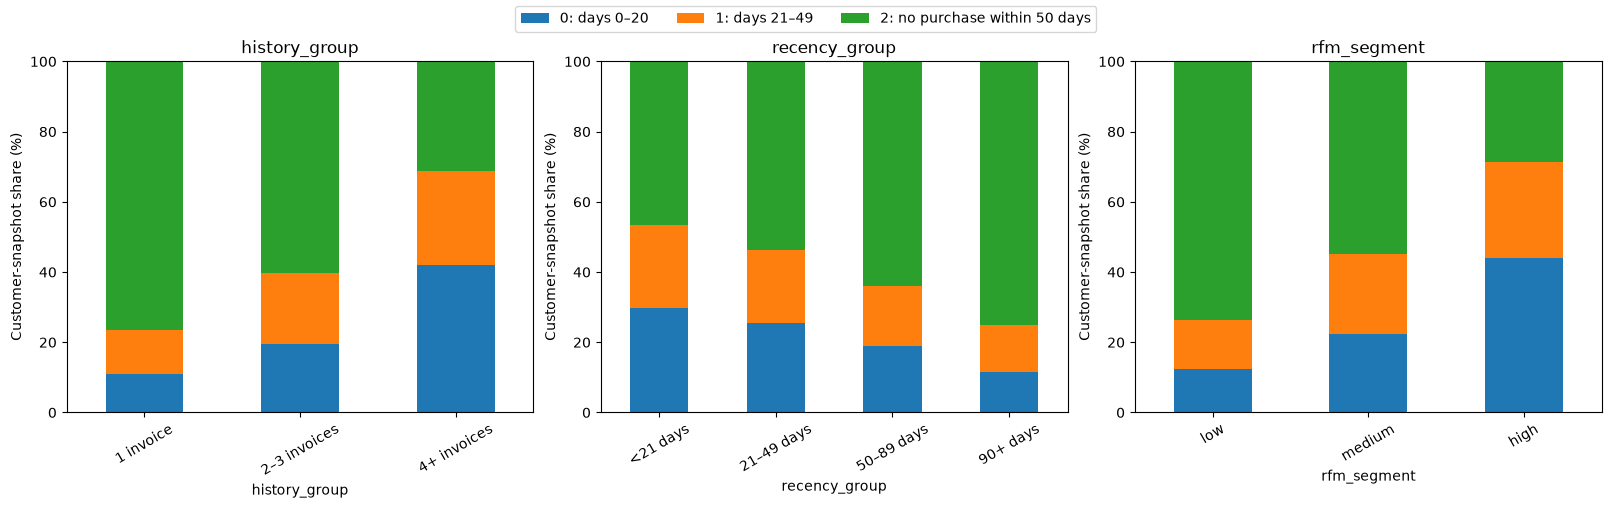

In [11]:
plot_group_outcomes(train, target)
plt.show()


In [12]:
# Show denominators alongside conditional outcome percentages.
rfm_outcomes = class_shares(train, target, "rfm_segment")
rfm_outcomes.insert(0, "snapshots", train.groupby("rfm_segment").size())
rfm_outcomes.reindex(["low", "medium", "high"]).round(2)


NextPurchaseRange,snapshots,0,1,2
rfm_segment,,,,
low,54461,12.42,13.80,73.77
medium,18216,22.22,22.89,54.89
high,19642,43.92,27.33,28.75


**Interpretation.** Frequent/recent profiles and higher RFM segments show larger
near-term purchase shares than sparse/inactive profiles. This supports evaluating
performance separately for one-invoice customers. Group differences do not prove
that an RFM score improves a classifier beyond continuous RFM inputs, or that an
offer would cause a purchase. Segment counts are customer-week counts.


In [13]:
comparison_columns = ["recency_days", "invoice_count", "monetary_total",
                      "observed_history_days", "invoice_count_30d", "monetary_30d",
                      "last_gap_days", "rfm_score"]
train.groupby(target)[comparison_columns].median().T


NextPurchaseRange,0,1,2
recency_days,32.477083,38.389931,66.619444
invoice_count,3.000000,2.000000,1.000000
monetary_total,1097.640000,807.100000,369.250000
observed_history_days,145.413194,139.474653,122.326389
invoice_count_30d,0.000000,0.000000,0.000000
monetary_30d,0.000000,0.000000,0.000000
last_gap_days,32.000000,45.000000,56.000000
rfm_score,66.666667,66.666667,33.333333


## Evolution of cumulative features

All-history totals and observed exposure tend to grow as the source accumulates
history. This is not automatically a seasonal effect. Calendar features have one
value per week: thousands of customer rows do not create thousands of independent
observations of a season. Training covers only part of an annual cycle.


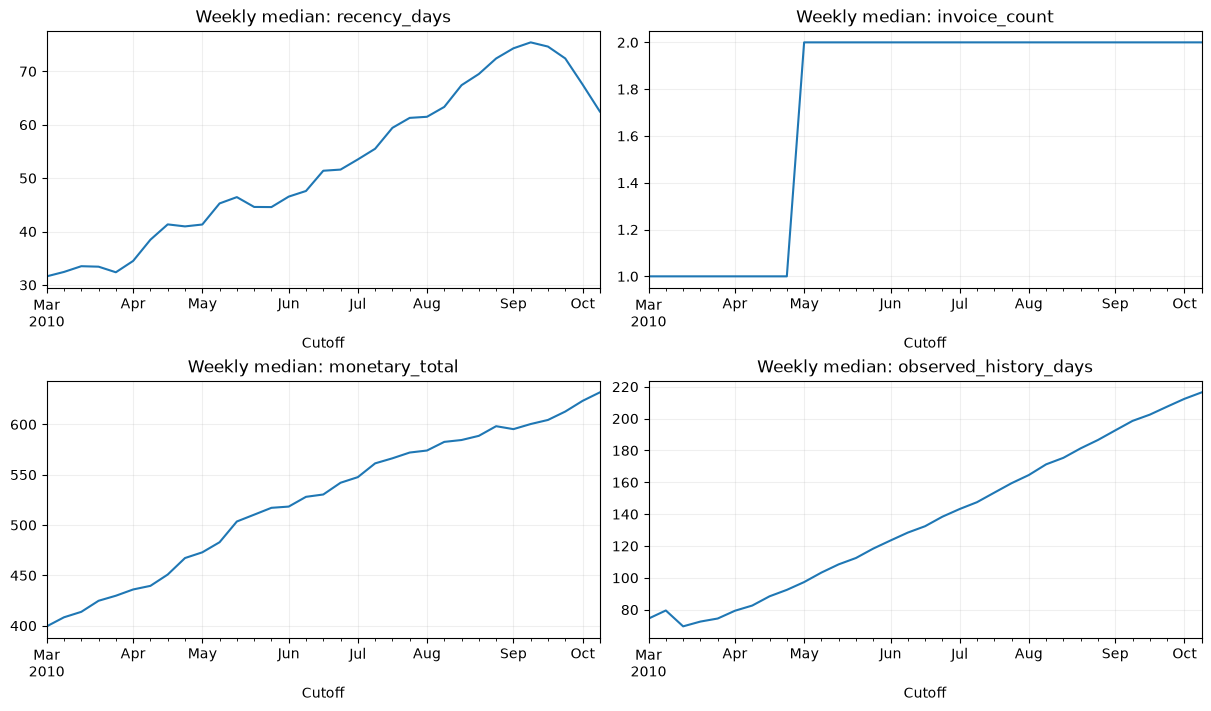

In [14]:
plot_weekly_feature_medians(train)
plt.show()

**Interpretation.** From the first to the last training cutoff, median observed
history increases from about 74 to 216 days, invoices from 1 to 2, and spend from
£399 to £632. Median recency also increases from about 32 to 62 days. Accumulating
history and retaining inactive customers can change these distributions; these
trends are not sufficient evidence of annual seasonality.


## Initial training observations

- Class proportions are approximately 21.06% (0), 18.48% (1), and 60.47% (2). A constant class-2 classifier would already reach about 60.47% pooled training accuracy; this is not a validated model result.
- One-invoice and long-inactive snapshots show higher non-purchase shares than frequent/recent profiles. This supports evaluating sparse-history customers separately.
- Higher relative RFM segments show more near-term purchases in training. This does not establish that the combined score improves predictions beyond continuous RFM features.
- Review the missingness table and weekly curves before choosing how to handle sparse histories or cumulative-feature growth. No predictors have been removed.
